t= 10.0
euler = -5.765636532941458
runge_kutta= -5.725783020533255
exact= -5.670609736317675


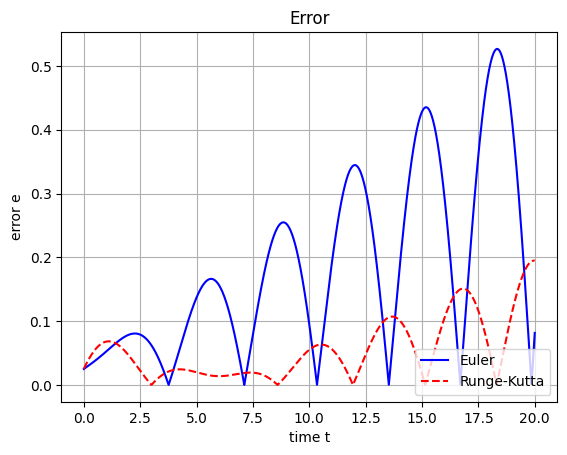

In [4]:
#!/usr/bin/env python
"""
Find the solution for the second order differential equation

u'' = -u

with u(0) = 10 and u'(0) = -5

using the Euler and the Runge-Kutta methods.

This works by splitting the problem into 2 first order differential equations

u' = v
v' = f(t,u)

with u(0) = 10 and v(0) = -5

"""

from math import cos, sin

def f(t, u):
    return -u

def exact(u0, du0, t):
    # analytical solution
    return u0 * cos(t) + du0 * sin(t)

def iterate(func, u, v, tmax, n):
    dt = tmax/(n-1)
    t = 0.0

    for i in range(n):
        u,v = func(u,v,t,dt)
        t += dt

    return u

def euler_iter(u, v, t, dt):
    v_new = v + dt * f(t, u)
    u_new = u + dt * v
    return u_new, v_new

def rk_iter(u, v, t, dt):
    k1 = f(t,u)
    k2 = f(t+dt*0.5,u+k1*0.5*dt)
    k3 = f(t+dt*0.5,u+k2*0.5*dt)
    k4 = f(t+dt,u+k3*dt)

    v += dt * (k1+2*k2+2*k3+k4)/6

    # v doesn't explicitly depend on other variables
    k1 = k2 = k3 = k4 = v

    u += dt * (k1+2*k2+2*k3+k4)/6

    return u,v

euler = lambda u, v, tmax, n: iterate(euler_iter, u, v, tmax, n)
runge_kutta = lambda u, v, tmax, n: iterate(rk_iter, u, v, tmax, n)

def plot_result(u, v, tmax, n):
    dt = tmax/(n-1)
    t = 0.0
    allt = []
    error_euler = []
    error_rk = []
    r_exact = []
    r_euler = []
    r_rk = []

    u0 = u_euler = u_rk = u
    v0 = v_euler = v_rk = v

    for i in range(n):
        u = exact(u0, v0, t)
        u_euler, v_euler = euler_iter(u_euler, v_euler, t, dt)
        u_rk, v_rk = rk_iter(u_rk, v_rk, t, dt)
        allt.append(t)
        error_euler.append(abs(u_euler-u))
        error_rk.append(abs(u_rk-u))
        r_exact.append(u)
        r_euler.append(u_euler)
        r_rk.append(u_rk)
        t += dt

    _plot("error.png", "Error", "time t", "error e", allt, error_euler, error_rk)
    #_plot("result.png", "Result", "time t", "u(t)", allt, r_euler, r_rk, r_exact)

def _plot(out, title, xlabel, ylabel, allt, euler, rk, exact=None):
    import matplotlib.pyplot as plt

    plt.title(title)

    plt.ylabel(ylabel)
    plt.xlabel(xlabel)

    plt.plot(allt, euler, 'b-', label="Euler")
    plt.plot(allt, rk, 'r--', label="Runge-Kutta")

    if exact:
        plt.plot(allt, exact, 'g.', label='Exact')

    plt.legend(loc=4)
    plt.grid(True)



u0 = 10
du0 = v0 = -5
tmax = 10.0
n = 2000

print("t=", tmax)
print("euler =", euler(u0, v0, tmax, n))
print("runge_kutta=", runge_kutta(u0, v0, tmax, n))
print("exact=", exact(u0, v0, tmax))

plot_result(u0, v0, tmax*2, n*2)